# GRU 게이트 순환 유닛 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week11/gru/lab/gru.ipynb)

문 두 개, 기억 하나: $\mathbf{h}_t = \mathbf{z}_t \odot \mathbf{h}_{t-1} + (1 - \mathbf{z}_t) \odot \tilde{\mathbf{h}}_t$ (원 논문 · PyTorch 와 같은 방향, $z$ = 지키는 비율).

- **파트 1**: 갱신 문 · 리셋 문 손 계산, numpy GRU 한 칸 → `nn.GRUCell` 과 비교
- **파트 2**: 셰익스피어 글자 모델 `nn.LSTM` vs `nn.GRU` (손실 · 가중치 수 · 한 걸음 시간)
- **파트 3**: 학습된 GRU 의 갱신 문 들여다보기, 글 써 보기

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요. 파트 2 는 몇 분 걸린다.

In [ ]:
import os, time
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn

## 파트 1. GRU 한 칸

먼저 문 값을 직접 넣은 손 계산 (슬라이드와 같은 숫자).
- 갱신 문: $h_{t-1} = 0.8$, $\tilde{h} = -0.2$, $z = 0.9$ → $h_t = 0.70$
- 리셋 문: $\tilde{h} = \tanh(w x + u (r h_{t-1}))$, $x = 1, w = 0.5, u = 2, h_{t-1} = 0.8$ → $r = 1$: 0.97, $r = 0$: 0.46

In [ ]:
def update(h_prev, z, h_tilde):
    return None  # TODO: keep z of the old memory, fill the rest with the candidate

def candidate(x, h_prev, r, w, u):
    return None  # TODO: candidate with the reset gate r

print("h_t =", round(update(0.8, 0.9, -0.2), 2))
for r in [1, 0.5, 0]:
    print(f"r = {r}: candidate = {candidate(1.0, 0.8, r, 0.5, 2.0):.2f}")

# How much of the old memory is left after 100 steps when z stays fixed (and nothing new comes in)
for z in [0.9, 0.99, 0.999]:
    print(f"z = {z}: {z ** 100 * 100:.3f}% left")

**예상 결과**

```
h_t = 0.7
r = 1: candidate = 0.97
r = 0.5: candidate = 0.86
r = 0: candidate = 0.46
z = 0.9: 0.003% left
z = 0.99: 36.603% left
z = 0.999: 90.479% left
```

이제 문도 직접 계산한다. PyTorch 는 세 묶음 가중치를 이어 붙여 두고, 순서는 **r, z, n** ($n$ = 후보 $\tilde{h}$).
PyTorch 의 후보는 리셋 문을 **곱한 뒤에** 곱한다: $n = \tanh(W_{in} x + b_{in} + r \odot (W_{hn} h + b_{hn}))$. 원 논문의 $W[r \odot h, x]$ 와 순서만 조금 다르다.

In [ ]:
def sigmoid(v):
    return 1 / (1 + np.exp(-v))

def gru_step(x, h, W_ih, W_hh, b_ih, b_hh):
    gi = W_ih @ x + b_ih                                 # 3 * hidden numbers (r, z, n)
    gh = W_hh @ h + b_hh
    ir, iz, i_n = np.split(gi, 3)
    hr, hz, h_n = np.split(gh, 3)
    r = sigmoid(ir + hr)
    z = sigmoid(iz + hz)
    n = None  # TODO: candidate (reset gate multiplies the h part)
    return None  # TODO: new memory

torch.manual_seed(0)
cell = nn.GRUCell(3, 2)
W_ih, W_hh = cell.weight_ih.detach().numpy(), cell.weight_hh.detach().numpy()
b_ih, b_hh = cell.bias_ih.detach().numpy(), cell.bias_hh.detach().numpy()
xs = np.array([[1.0, 0.0, -1.0], [0.5, 0.5, 0.5], [0.0, 1.0, 0.0]])

h, ht = np.zeros(2), torch.zeros(1, 2)
for x in xs:
    h = gru_step(x, h, W_ih, W_hh, b_ih, b_hh)
    with torch.no_grad():
        ht = cell(torch.tensor(x, dtype=torch.float32)[None], ht)
    print("numpy h:", h.round(4), "  torch h:", ht[0].numpy().round(4))

**예상 결과**

```
numpy h: [-0.3646 -0.3562]   torch h: [-0.3646 -0.3562]
numpy h: [-0.603  -0.3621]   torch h: [-0.603  -0.3621]
numpy h: [-0.6736 -0.3724]   torch h: [-0.6736 -0.3724]
```

## 파트 2. LSTM vs GRU

셰익스피어 글자 모델 (RNN · LSTM 시간과 같다). 순환 층만 바꿔 끼운다. 학습은 앞 90% 글, 검증 손실은 뒤 10% 글로 잰다.

In [ ]:
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
os.makedirs("data", exist_ok=True)
if not os.path.exists("data/shakespeare.txt"):
    import urllib.request; urllib.request.urlretrieve(url, "data/shakespeare.txt")
text = open("data/shakespeare.txt").read()
chars = sorted(set(text)); stoi = {c: i for i, c in enumerate(chars)}
data = torch.tensor([stoi[c] for c in text])
cut = int(len(data) * 0.9)
train_data, val_data = data[:cut], data[cut:]
print(len(train_data), "train characters,", len(val_data), "validation characters,", len(chars), "distinct")

**예상 결과**

```
1003854 train characters, 111540 validation characters, 65 distinct
```

In [ ]:
class CharModel(nn.Module):
    def __init__(self, kind, vocab, hidden=128):
        super().__init__()
        self.emb = nn.Embedding(vocab, hidden)
        self.rnn = {"lstm": nn.LSTM, "gru": nn.GRU}[kind](hidden, hidden, batch_first=True)
        self.out = nn.Linear(hidden, vocab)

    def forward(self, x, state=None):
        o, state = self.rnn(self.emb(x), state)          # LSTM state = (h, c), GRU state = h
        return self.out(o), state

def get_batch(data, seq=64, batch=64, gen=None):
    ix = torch.randint(0, len(data) - seq - 1, (batch,), generator=gen)
    x = torch.stack([data[i:i + seq] for i in ix])
    y = torch.stack([data[i + 1:i + seq + 1] for i in ix])
    return x, y

def train(kind, train_data, vocab, steps=1000):
    torch.manual_seed(0)
    model = CharModel(kind, vocab)
    opt = torch.optim.Adam(model.parameters(), 3e-3); gen = torch.Generator().manual_seed(0)
    losses, t0 = [], time.perf_counter()
    for step in range(steps):
        x, y = get_batch(train_data, gen=gen)
        logits, _ = model(x)
        loss = nn.functional.cross_entropy(logits.reshape(-1, vocab), y.reshape(-1))
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        losses.append(loss.item())
    return model, losses, (time.perf_counter() - t0) / steps

def val_loss(model, val_data, vocab):
    x, y = get_batch(val_data, batch=200, gen=torch.Generator().manual_seed(1))
    with torch.no_grad():
        logits, _ = model(x)
    return nn.functional.cross_entropy(logits.reshape(-1, vocab), y.reshape(-1)).item()

def count_params(module):
    return None  # TODO: total number of weights

models = {}
for kind in ["lstm", "gru"]:
    model, losses, sec = train(kind, train_data, len(chars))
    models[kind] = model
    print(f"{kind:4s} validation loss {val_loss(model, val_data, len(chars)):.3f}   "
          f"recurrent weights {count_params(model.rnn):7,d}   {sec * 1000:.0f} ms/step")
    plt.plot(np.convolve(losses, np.ones(50) / 50, mode="valid"), label=kind)
plt.xlabel("step"); plt.ylabel("training loss (50-step average)"); plt.legend(); plt.show()
print("GRU / LSTM weights:", count_params(models["gru"].rnn) / count_params(models["lstm"].rnn))

**예상 결과**

```
lstm validation loss 1.696   recurrent weights 132,096   17 ms/step
gru  validation loss 1.701   recurrent weights  99,072   12 ms/step
GRU / LSTM weights: 0.75
```

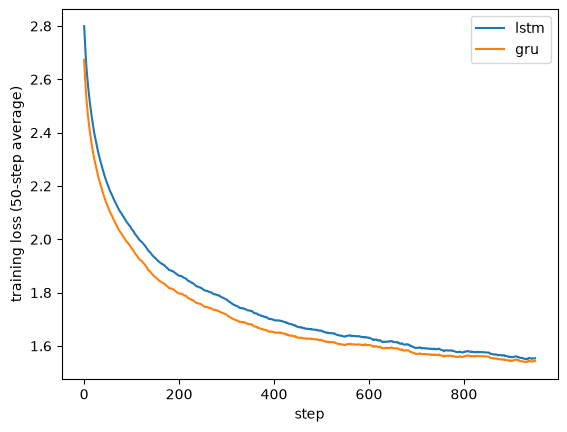

한 걸음 시간은 컴퓨터마다 다르다 (CPU · GPU, 다른 일이 돌고 있는지). 가중치 수의 비 $\frac34$ 는 어디서나 같다.

## 파트 3. 갱신 문 들여다보기

학습된 `nn.GRU` 의 가중치로 한 글자씩 직접 계산하며, 글자마다 갱신 문 $z$ 의 평균 (128칸 평균) 을 잰다. $z$ 가 작으면 그 글자에서 기억을 많이 **새로 쓴** 것이다.

In [ ]:
def update_gates(gru, emb, ids):
    W_ih, W_hh = gru.weight_ih_l0, gru.weight_hh_l0
    b_ih, b_hh = gru.bias_ih_l0, gru.bias_hh_l0
    h, zs = torch.zeros(gru.hidden_size), []
    with torch.no_grad():
        for i in ids:
            gi, gh = W_ih @ emb.weight[i] + b_ih, W_hh @ h + b_hh
            ir, iz, i_n = gi.chunk(3); hr, hz, h_n = gh.chunk(3)
            r, z = torch.sigmoid(ir + hr), torch.sigmoid(iz + hz)
            n = torch.tanh(i_n + r * h_n)
            h = z * h + (1 - z) * n
            zs.append(None)  # TODO: average update gate over the 128 cells
    return zs

snippet = text[cut + 200: cut + 260]
zs = update_gates(models["gru"].rnn, models["gru"].emb, [stoi[c] for c in snippet])
plt.figure(figsize=(14, 3))
plt.bar(range(len(snippet)), zs)
plt.xticks(range(len(snippet)), [c if c != "\n" else "\\n" for c in snippet])
plt.ylabel("mean update gate z"); plt.ylim(0, 1); plt.show()
low = sorted(range(len(snippet)), key=lambda k: zs[k])[:5]
print("lowest z (most rewriting) at:", [repr(snippet[k]) for k in low])

**예상 결과**

```
lowest z (most rewriting) at: ["' '", "','", "'?'", "' '", "' '"]
```

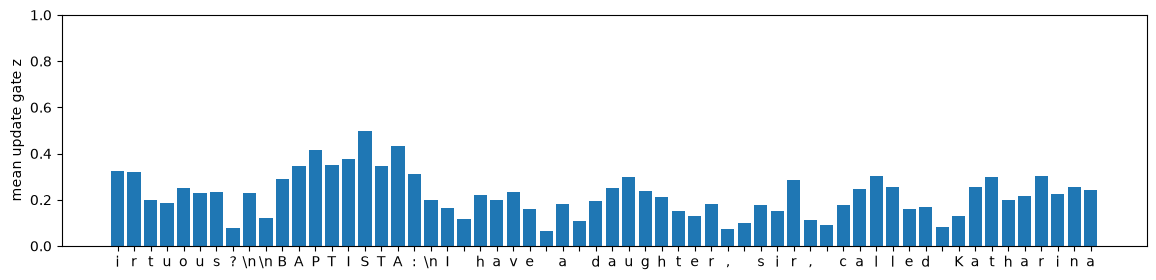

In [ ]:
def generate(model, start, stoi, chars, n=300, temperature=0.8, seed=0):
    g = torch.Generator().manual_seed(seed)
    x = torch.tensor([[stoi[c] for c in start]]); out = start
    with torch.no_grad():
        logits, state = model(x)
        for _ in range(n):
            p = torch.softmax(logits[0, -1] / temperature, dim=0)
            c = torch.multinomial(p, 1, generator=g).item()
            out += chars[c]
            logits, state = model(torch.tensor([[c]]), state)
    return out

print(generate(models["gru"], "ROMEO:", stoi, chars, 250))

**예상 결과**

```
ROMEO:
Why more know the fied, and that you wiltle fall come with that here hath good being stones,
For that of the way we are send the earner mothers!
When hot to a man is his gods! what the well, and. So I fearful him-milk my honours,
Think of me fles we
```

**확인 질문**
1. 파트 1 에서 $z = 0$ 이면 새 기억은? $z = 1$ 이면? 각각 어떤 상황에 쓸모 있을까?
2. 파트 2 에서 GRU 와 LSTM 의 검증 손실 차이는 얼마였나? 가중치 차이 (몇 \%) 와 비교하면?
3. 파트 3 에서 $z$ 가 가장 작았던 글자는 무엇이었나? 공백 · 줄바꿈 · 대문자 근처인가?
4. (도전) `get_batch` 의 `seq` 를 128 로 늘려 다시 비교하면 차이가 커지나?

데이터 출처: Tiny Shakespeare, Andrej Karpathy char-rnn (2015).